In [1]:
import pandas as pd 
import numpy as np

In [7]:
import os
print(os.getcwd())


C:\Users\TANUSHREE\Oasis Infobyte


In [8]:
os.listdir()

['.ipynb_checkpoints',
 'Cleaning Dataset.ipynb',
 'EDA on Retail Sales Data.ipynb',
 'house_prices.csv',
 'messy_retail_sales_dataset.csv',
 'OnlineRetail.csv',
 'Predicting House Prices with Linear Regression.ipynb']

In [10]:
df=pd.read_csv("house_prices.csv")
df.head()

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,2ndFlrSF,YearBuilt,Bedrooms,Bathrooms,HouseAge,YearsSinceRemodel,Neighborhood,SalePrice
0,8,1648,2,526,656,555,567,1956,3,3.0,70,58,NridgHt,524931.0
1,6,1218,2,485,795,1327,883,1944,2,2.0,82,60,Mitchel,379701.0
2,5,1102,2,430,1090,1338,876,2011,3,0.5,15,13,Sawyer,355598.0
3,6,1973,3,591,962,1469,292,1991,3,1.0,35,21,Crawfor,497050.0
4,8,1471,1,400,1334,948,518,1990,3,1.0,36,18,Crawfor,518391.0


In [12]:
df.shape

(1460, 14)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   OverallQual        1460 non-null   int64  
 1   GrLivArea          1460 non-null   int64  
 2   GarageCars         1460 non-null   int64  
 3   GarageArea         1460 non-null   int64  
 4   TotalBsmtSF        1460 non-null   int64  
 5   1stFlrSF           1460 non-null   int64  
 6   2ndFlrSF           1460 non-null   int64  
 7   YearBuilt          1460 non-null   int64  
 8   Bedrooms           1460 non-null   int64  
 9   Bathrooms          1460 non-null   float64
 10  HouseAge           1460 non-null   int64  
 11  YearsSinceRemodel  1460 non-null   int64  
 12  Neighborhood       1460 non-null   str    
 13  SalePrice          1460 non-null   float64
dtypes: float64(2), int64(11), str(1)
memory usage: 169.4 KB


In [14]:
df.dtypes

OverallQual            int64
GrLivArea              int64
GarageCars             int64
GarageArea             int64
TotalBsmtSF            int64
1stFlrSF               int64
2ndFlrSF               int64
YearBuilt              int64
Bedrooms               int64
Bathrooms            float64
HouseAge               int64
YearsSinceRemodel      int64
Neighborhood             str
SalePrice            float64
dtype: object

In [15]:
df.columns

Index(['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
       '1stFlrSF', '2ndFlrSF', 'YearBuilt', 'Bedrooms', 'Bathrooms',
       'HouseAge', 'YearsSinceRemodel', 'Neighborhood', 'SalePrice'],
      dtype='str')

In [16]:
df.isnull().sum().sum()

np.int64(0)

In [17]:
df.describe

<bound method NDFrame.describe of       OverallQual  GrLivArea  GarageCars  GarageArea  TotalBsmtSF  1stFlrSF  \
0               8       1648           2         526          656       555   
1               6       1218           2         485          795      1327   
2               5       1102           2         430         1090      1338   
3               6       1973           3         591          962      1469   
4               8       1471           1         400         1334       948   
...           ...        ...         ...         ...          ...       ...   
1455            7       1518           1         322         1614       923   
1456            7       1687           2         545          581      1814   
1457            5       1531           3         745          594       638   
1458            7       1882           1         316          956      1249   
1459            5       1192           3         659          923      1187   

      2ndFlrSF  Y

In [18]:
df['SalePrice'].describe()

count      1460.000000
mean     426987.942466
std       79259.373413
min      178829.000000
25%      374372.500000
50%      420691.500000
75%      477423.750000
max      750000.000000
Name: SalePrice, dtype: float64

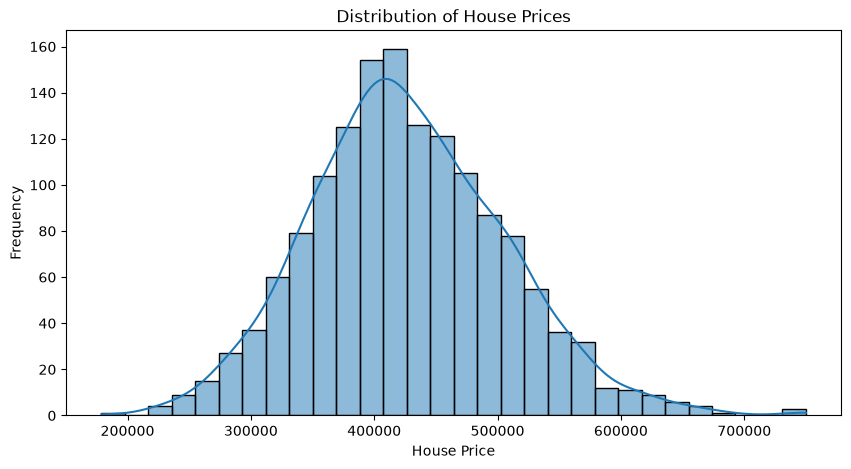

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10,5))
sns.histplot(df['SalePrice'], bins=30, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('House Price')
plt.ylabel('Frequency')
plt.show()

OverallQual: The overall quality of a house can strongly influence its selling price.
GrLivArea: Houses with larger living areas generally have higher market value.
GarageCars and GarageArea: Garage capacity and size can affect property value.
TotalBsmtSF: Basement area contributes to the overall usable space.
YearBuilt and HouseAge: The construction year and age of a house can influence its condition and value.
Bedrooms and Bathrooms: The number of bedrooms and bathrooms affects the suitability of a house for buyers.
Neighborhood: Location is an important factor because property prices vary across different areas.
YearsSinceRemodel: Recently renovated houses may attract higher prices.

In [24]:
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include='object').columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
print("Missing values after handling:")
print(df.isnull().sum().sum())

Missing values after handling:
0


C:\Users\TANUSHREE\AppData\Local\Temp\ipykernel_23408\1514255876.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


In [25]:
cat_cols = df.select_dtypes(include=['object']).columns

print("Categorical Columns:")
print(cat_cols)

Categorical Columns:
Index(['Neighborhood'], dtype='str')


C:\Users\TANUSHREE\AppData\Local\Temp\ipykernel_23408\2685251121.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [26]:
# Separate target and input features
X = df.drop('SalePrice', axis=1)
y = df['SalePrice']
# Apply One-Hot Encoding
X_encoded = pd.get_dummies(
    X,
    columns=['Neighborhood'],
    drop_first=True,
    dtype=int)
# Combine encoded features with target
df_encoded = pd.concat([X_encoded, y], axis=1)
df_encoded.head()

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,2ndFlrSF,YearBuilt,Bedrooms,Bathrooms,...,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_Sawyer,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,SalePrice
0,8,1648,2,526,656,555,567,1956,3,3.0,...,0,0,1,0,0,0,0,0,0,524931.0
1,6,1218,2,485,795,1327,883,1944,2,2.0,...,0,0,0,0,0,0,0,0,0,379701.0
2,5,1102,2,430,1090,1338,876,2011,3,0.5,...,0,0,0,0,1,0,0,0,0,355598.0
3,6,1973,3,591,962,1469,292,1991,3,1.0,...,0,0,0,0,0,0,0,0,0,497050.0
4,8,1471,1,400,1334,948,518,1990,3,1.0,...,0,0,0,0,0,0,0,0,0,518391.0


In [27]:
print("Original Dataset Shape:", df.shape)
print("Encoded Dataset Shape:", df_encoded.shape)
print("\nEncoded Columns:")
print(df_encoded.columns.tolist())

Original Dataset Shape: (1460, 14)
Encoded Dataset Shape: (1460, 30)

Encoded Columns:
['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'YearBuilt', 'Bedrooms', 'Bathrooms', 'HouseAge', 'YearsSinceRemodel', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr', 'Neighborhood_Crawfor', 'Neighborhood_Edwards', 'Neighborhood_Gilbert', 'Neighborhood_Mitchel', 'Neighborhood_NAmes', 'Neighborhood_NWAmes', 'Neighborhood_NoRidge', 'Neighborhood_NridgHt', 'Neighborhood_OldTown', 'Neighborhood_Sawyer', 'Neighborhood_Somerst', 'Neighborhood_StoneBr', 'Neighborhood_Timber', 'Neighborhood_Veenker', 'SalePrice']


In [28]:
print("Missing Values:", df_encoded.isnull().sum().sum())
print("Duplicate Rows:", df_encoded.duplicated().sum())
df_encoded.head()

Missing Values: 0
Duplicate Rows: 0


,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,2ndFlrSF,YearBuilt,Bedrooms,Bathrooms,...,Neighborhood_NWAmes,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_Sawyer,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,SalePrice
0,8,1648,2,526,656,555,567,1956,3,3.0,...,0,0,1,0,0,0,0,0,0,524931.0
1,6,1218,2,485,795,1327,883,1944,2,2.0,...,0,0,0,0,0,0,0,0,0,379701.0
2,5,1102,2,430,1090,1338,876,2011,3,0.5,...,0,0,0,0,1,0,0,0,0,355598.0
3,6,1973,3,591,962,1469,292,1991,3,1.0,...,0,0,0,0,0,0,0,0,0,497050.0
4,8,1471,1,400,1334,948,518,1990,3,1.0,...,0,0,0,0,0,0,0,0,0,518391.0


The dataset is now prepared for further machine learning preprocessing. Missing values have been handled, and categorical features have been converted into numerical format. The target variable SalePrice was kept separate from the input features during encoding.

In [29]:
correlation_matrix = df_encoded.corr(numeric_only=True)

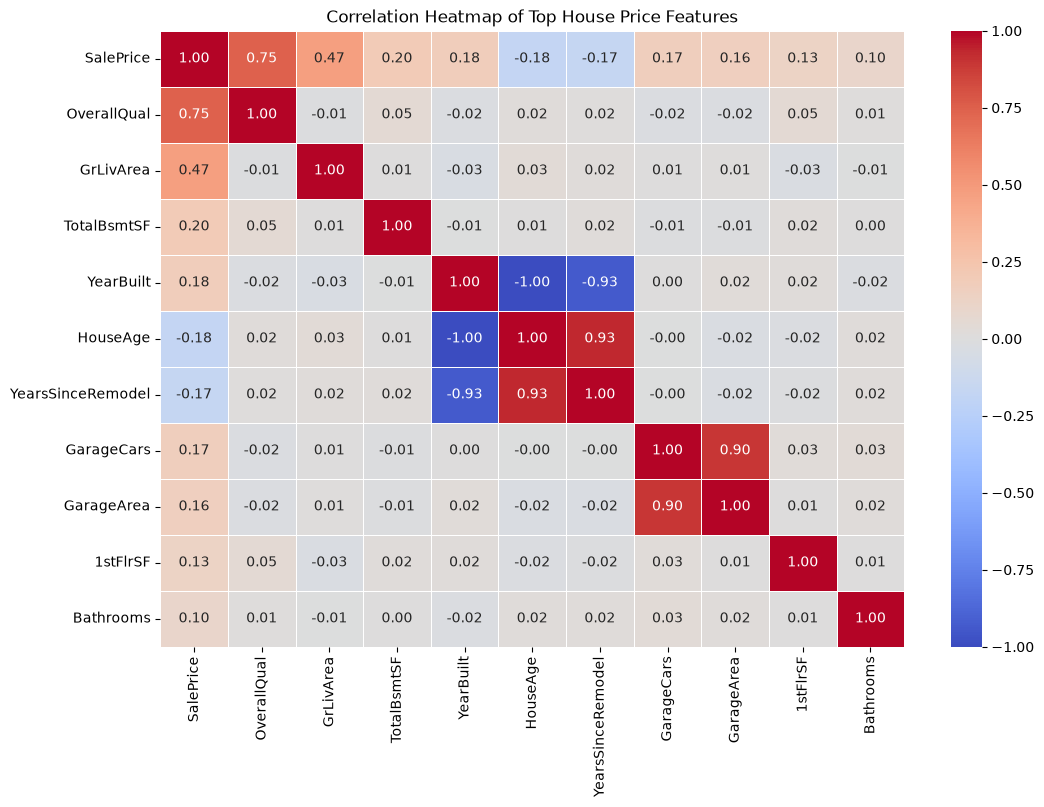

In [30]:
# Calculate correlation with SalePrice
price_corr = df_encoded.corr(numeric_only=True)['SalePrice']

# Select 10 features with highest absolute correlation
top_features = price_corr.abs().sort_values(ascending=False).head(11).index

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df_encoded[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Top House Price Features')
plt.show()

In [31]:
correlation = df_encoded.corr(numeric_only=True)['SalePrice']

correlation = correlation.drop('SalePrice')

correlation = correlation.reindex(
    correlation.abs().sort_values(ascending=False).index
)

print("Features most correlated with SalePrice:")
print(correlation)

Features most correlated with SalePrice:
OverallQual             0.746756
GrLivArea               0.473249
TotalBsmtSF             0.201649
YearBuilt               0.175512
HouseAge               -0.175512
YearsSinceRemodel      -0.169378
GarageCars              0.165257
GarageArea              0.162855
1stFlrSF                0.129896
Bathrooms               0.097167
Neighborhood_NoRidge    0.092062
Neighborhood_Sawyer    -0.081210
2ndFlrSF                0.054928
Bedrooms                0.051239
Neighborhood_StoneBr    0.050011
Neighborhood_Timber     0.044730
Neighborhood_Gilbert   -0.043274
Neighborhood_NAmes     -0.042938
Neighborhood_CollgCr   -0.040514
Neighborhood_BrkSide   -0.039855
Neighborhood_NridgHt    0.034824
Neighborhood_Veenker    0.023689
Neighborhood_ClearCr    0.022841
Neighborhood_Edwards    0.020523
Neighborhood_NWAmes    -0.019541
Neighborhood_Mitchel    0.013389
Neighborhood_Crawfor   -0.009743
Neighborhood_OldTown   -0.005387
Neighborhood_Somerst    0.005155
Na

OverallQual and GrLivArea are the strongest numerical predictors of house prices in this dataset. These features may be useful for building a house price prediction model. Correlation indicates association, not necessarily causation.

In [40]:
from sklearn.model_selection import train_test_split

In [41]:
X = df_encoded.drop('SalePrice', axis=1)
y = df_encoded['SalePrice']

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [43]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1168, 29)
X_test shape: (292, 29)
y_train shape: (1168,)
y_test shape: (292,)


In [44]:
print("Total records:", len(X_train) + len(X_test))
print("Training percentage:", len(X_train)/len(X)*100)
print("Testing percentage:", len(X_test)/len(X)*100)

Total records: 1460
Training percentage: 80.0
Testing percentage: 20.0


In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [49]:
lr_model=LinearRegression()
print("Linear Regression model created successfully")

Linear Regression model created successfully


In [50]:
lr_model.fit(X_train,y_train)
print("Linear Regression model Trained Successfully")

Linear Regression model Trained Successfully


In [51]:
# Predict house prices
y_pred = lr_model.predict(X_test)

print("Predicted House Prices:")
print(y_pred[:10])

Predicted House Prices:
[459073.68453112 337461.79463436 437145.29493686 504997.41152814
 247933.95510026 514693.49599399 511187.16620451 419174.37713339
 375451.93013579 435280.48390954]


In [52]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,451529.0,459073.684531
1,342758.0,337461.794634
2,452546.0,437145.294937
3,475480.0,504997.411528
4,252615.0,247933.955100
5,513270.0,514693.495994
6,517053.0,511187.166205
7,420252.0,419174.377133
8,370844.0,375451.930136
9,427176.0,435280.483910


In [53]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("Linear Regression Model Performance")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Model Performance
MAE: 16390.297224577578
MSE: 455560092.24780387
RMSE: 21343.853734689146
R2 Score: 0.9355678067812538


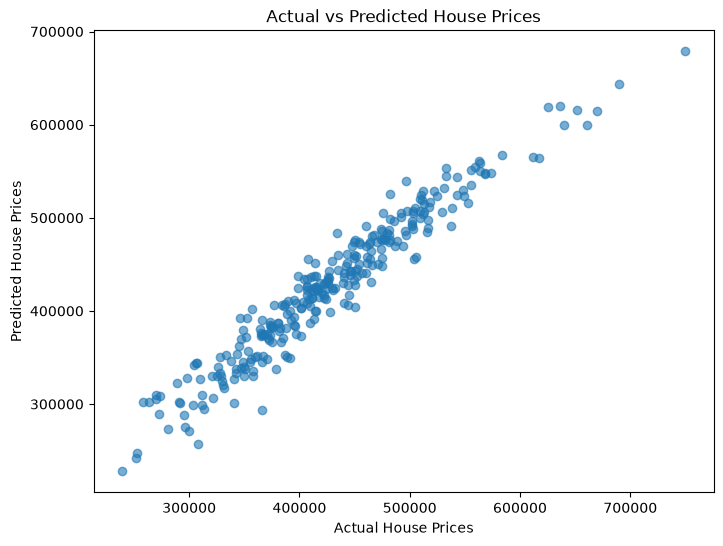

In [54]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()

The Linear Regression Model was successfully trained and used to predict the house prices.The model was trained using 80% of the dataset and tested using remaining 20% .
The fit() function was used to train the model, and the predict() function eas used to generate the house price predictions.
The model performance was evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score.
A scatter plot was created to compare actual house prices with predicted house prices.